# Dutch boys' BMI: growth centiles with BCCG

The goal is to place a boy's BMI relative to his peers: whether he sits on the
3rd centile, the 50th, or the 97th.

That is a question about position within a distribution, so it requires the
whole distribution of BMI at that age — its centre, spread and skewness. A
conditional mean supplies only the centre. This study builds such a chart, and
in the course of it encounters a numerical rather than statistical failure: the
fit diverges because the default step length is too large for the scale of the
response.

A distributional model produces age-specific centiles, and a numerically unstable fit can be diagnosed before its curves are read. The deliverable is a
centile chart, not a mean regression line.


:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | placing a boy's BMI against his peers — 3rd centile, 50th, or 97th |
| **Observed response** | `bmi`, body mass index |
| **Estimand** | conditional centiles of BMI given age, which requires the whole conditional distribution rather than its mean |
| **Units** | BMI in kg/m²; age in years |
| **Sampling unit** | one boy; 7294 in a cross-sectional growth study |
| **Dependence** | cross-sectional — one measurement per boy, so no within-child correlation |
| **Split / resampling unit** | the boy |
| **Tuning** | fixed `mstop` per parameter |
| **Uncertainty** | expressed as the centile spread itself |
| **Claim type** | descriptive. A centile places a child in a reference population; it makes no predictive or causal claim |
:::


## The data

7294 Dutch boys from the Fourth Dutch Growth Study, distributed with
`gamlss.data` as `dbbmi`, where it is the standard illustration for the LMS
centile method, which describes each age by three parameters: L (the Box-Cox power, which sets skewness), M (the centre) and S (the spread). Two columns: age in years and BMI.

One country, one survey period, boys only. These centiles describe boys in the surveyed Dutch population. Applying them
to another population requires a check of calibration or re-estimation.


In [1]:
import numpy as np
import polars as pl

import mboostrs as mb

data = mb.datasets.dutchboys(output="records")
n = len(data["age"])
age = np.asarray(data["age"])
bmi = np.asarray(data["bmi"])
terms = "bmi ~ bbs(age, df=6)"

edges = np.quantile(age, [0, 0.2, 0.4, 0.6, 0.8, 1.0])
rows = []
for i in range(5):
    band = (age >= edges[i]) & (age <= edges[i + 1])
    values = bmi[band]
    standardised = (values - values.mean()) / values.std(ddof=1)
    rows.append({
        "age band": f"{edges[i]:.1f}-{edges[i + 1]:.1f}",
        "n": int(band.sum()),
        "mean BMI": round(float(values.mean()), 2),
        "sd": round(float(values.std(ddof=1)), 2),
        "skewness": round(float((standardised ** 3).mean()), 2),
    })
display(pl.DataFrame(rows))

age band,n,mean BMI,sd,skewness
str,i64,f64,f64,f64
"""0.0-1.3""",1465,16.52,1.7,0.06
"""1.3-7.3""",1462,16.19,1.43,0.52
"""7.3-12.5""",1459,17.02,2.26,1.28
"""12.5-16.0""",1465,19.1,2.54,1.05
"""16.0-21.7""",1461,21.32,2.66,0.93


All three moments change with age. The mean dips and then climbs, the spread
grows by about half, and the skewness rises from near zero in infancy to
strongly right-skewed in later childhood before easing.

A centile chart has to track all three. Modelling the mean and spread while
assuming symmetry places the 3rd and 97th centiles incorrectly, and in opposite
directions.


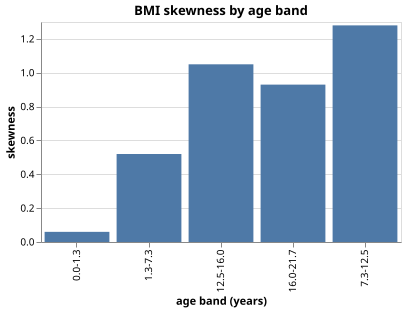

In [2]:
import altair as alt

skew_df = pl.DataFrame([
    {"age band": r["age band"], "skewness": r["skewness"]} for r in rows
])
alt.Chart(skew_df).mark_bar(color="#4e79a7").encode(
    x=alt.X("age band:O", title="age band (years)"),
    y=alt.Y("skewness:Q", title="skewness"),
).properties(title="BMI skewness by age band", width=360, height=220)

## Gaussian location-scale centiles

A Gaussian location-scale model, smooth in age for both parameters. It accounts
for the first two moments, which is more than a regression on the mean
provides.

We first check centile coverage: whether 3% of boys fall below the fitted
3rd centile.


In [3]:
def evaluate(label, family, specification, step, mstop=1500):
    fit = mb.gamboostLSS(specification, data=data, families=family,
                         control=mb.boost_control(mstop, step))
    values = np.asarray(fit.pit(random_state=0))
    observed, _ = np.histogram(values, bins=10, range=(0, 1))
    centiles = np.asarray(fit.centiles(probs=[0.03, 0.5, 0.97]))
    return fit, {
        "model": label,
        "step": step,
        "final risk": round(float(np.asarray(fit.risk_)[-1]), 1),
        "PIT chi-square": round(float(((observed - n / 10) ** 2 / (n / 10)).sum()), 1),
        "below 3rd": f"{np.mean(bmi < centiles[:, -3]) * 100:.2f}%",
        "above 97th": f"{np.mean(bmi > centiles[:, -1]) * 100:.2f}%",
    }


gaussian_spec = {"mu": terms, "sigma": terms}
gaussian, gaussian_row = evaluate("GaussianLSS", mb.GaussianLSS(),
                                  gaussian_spec, step=0.1)
display(pl.DataFrame([gaussian_row]))
print("targets: 3.00% below the 3rd centile, 3.00% above the 97th")

model,step,final risk,PIT chi-square,below 3rd,above 97th
str,f64,f64,f64,str,str
"""GaussianLSS""",0.1,15204.6,312.0,"""1.10%""","""4.29%"""


targets: 3.00% below the 3rd centile, 3.00% above the 97th


The fitted 3rd centile has 1.10% of boys below it, and the fitted 97th has
4.29% above it, against a target of 3% for each. Both fitted lines are too low
by this empirical coverage check.

This is the pattern produced by unmodelled right skew. The observed
distribution has a longer upper tail than a normal, and a symmetric fit
cannot reproduce both tails. Here both centiles are too low; the observed
coverage, rather than symmetry alone, determines the direction of each error. The PIT chi-square (the chi-square statistic for the probability integral transform, which is the fitted cumulative distribution applied to each observation and is uniform when the fit is right) is 312 against a critical value of 16.9 on 9 degrees of freedom.


## BCCG fit at the default step length

The Box-Cox-Cole-Green distribution adds a third parameter, ν, controlling
skewness. ν is the skewness parameter; the step length, also called `nu` in the code, is a separate setting. It is the distribution behind the LMS method, whose L, M and S are
its ν, μ and σ. Making ν smooth in age allows the skew to change along the
chart, which the age-band table indicates it must.


In [4]:
bccg_spec = {"mu": terms, "sigma": terms, "nu": terms}
_, bccg_default = evaluate("BCCGLSS", mb.BCCGLSS(), bccg_spec, step=0.1)
display(pl.DataFrame([gaussian_row, bccg_default]))

model,step,final risk,PIT chi-square,below 3rd,above 97th
str,f64,f64,f64,str,str
"""GaussianLSS""",0.1,15204.6,312.0,"""1.10%""","""4.29%"""
"""BCCGLSS""",0.1,20284.9,10584.0,"""1.17%""","""0.00%"""


No boys fall above the fitted 97th centile, the PIT chi-square is in the ten
thousands, and the final risk of 20284.9 exceeds the Gaussian model's 15204.6.
BCCG models positive responses through a Box-Cox transformation; it does not
contain the unrestricted Gaussian family as an exact special case. To assess
whether this fit has a numerical problem, we inspect its own risk path.


## Numerical diagnostic: BCCG risk path

Boosting minimises in-sample risk directly, so the risk should fall along the
path. Here it rises.


In [5]:
diverging = mb.gamboostLSS(bccg_spec, data=data, families=mb.BCCGLSS(),
                          control=mb.boost_control(400, 0.1))
path = np.asarray(diverging.risk_)
print(f"risk at iteration   0: {path[0]:9.1f}   (the offset-only fit)")
for m in (5, 10, 50, 200, 400):
    print(f"risk at iteration {m:3d}: {path[m]:9.1f}")
print(f"\nthe risk rises above its starting value and never returns")

risk at iteration   0:   17688.4   (the offset-only fit)
risk at iteration   5:   19158.1
risk at iteration  10:   21467.5
risk at iteration  50:   20373.8
risk at iteration 200:   20337.6
risk at iteration 400:   20306.4

the risk rises above its starting value and never returns


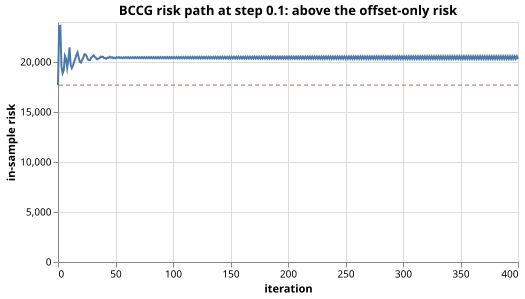

In [6]:
import altair as alt

risk_df = pl.DataFrame({"iteration": np.arange(len(path)), "risk": path})
line = alt.Chart(risk_df).mark_line(color="#4e79a7").encode(
    x=alt.X("iteration:Q", title="iteration"),
    y=alt.Y("risk:Q", title="in-sample risk"),
)
start = alt.Chart(pl.DataFrame({"y": [path[0]]})).mark_rule(
    color="#e15759", strokeDash=[4, 3]
).encode(y="y:Q")
(line + start).properties(
    title="BCCG risk path at step 0.1: above the offset-only risk",
    width=460, height=240,
)

The offset-only risk is 17688.4. The path starts there, rises to about 21467 at
iteration 10, settles near 20300, and does not return to its starting value. At
1500 iterations it stands at 20284.9.

Boosting takes a step proportional to the negative gradient with a fixed step
length, which works when the risk is gently curved near the current fit. This
risk surface is steep: BMI's log-scale spread is about 0.15 and the Box-Cox
residual is divided by it, so a step of 0.1 overshoots the minimum repeatedly
and in a direction that compounds. The remedy is the step length rather than
the family.

```{note}
A rising in-sample risk path indicates a failure of the optimisation rather
than of the model. The step length is too large for the curvature of the risk
surface; reducing `nu` and increasing `mstop` compensates. The stored risk path allows this numerical check before interpreting the
centile curves.
```


## BCCG fit with a smaller step length

Both families are fitted at step 0.01. The step length is set by one criterion: the in-sample risk must fall along the path. The Gaussian fit serves as a
control: if the improvement appeared in the Gaussian row as well, the step
length rather than the third parameter would account for it.


In [7]:
comparison = [gaussian_row, bccg_default]
gaussian_small, gaussian_small_row = evaluate("GaussianLSS", mb.GaussianLSS(),
                                              gaussian_spec, step=0.01)
bccg, bccg_row = evaluate("BCCGLSS", mb.BCCGLSS(), bccg_spec, step=0.01)
comparison += [gaussian_small_row, bccg_row]
display(pl.DataFrame(comparison))

model,step,final risk,PIT chi-square,below 3rd,above 97th
str,f64,f64,f64,str,str
"""GaussianLSS""",0.1,15204.6,312.0,"""1.10%""","""4.29%"""
"""BCCGLSS""",0.1,20284.9,10584.0,"""1.17%""","""0.00%"""
"""GaussianLSS""",0.01,15452.6,284.2,"""0.89%""","""4.50%"""
"""BCCGLSS""",0.01,14731.7,53.0,"""1.97%""","""3.73%"""


At step 0.01 the BCCG fit converges. Its final risk is the lowest of the four,
the PIT chi-square falls from 10584 to 53.0, and the centiles are close to
their targets: 1.97% below the 3rd and 3.73% above the 97th, against 1.10% and
4.29% for the Gaussian.

The Gaussian comparison changes much less at the smaller step: final risk
15452.6 against 15204.6, PIT 284.2 against 312.0. The large BCCG improvement
therefore accompanies stable fitting of that family, rather than a similar
improvement in both families from reducing the step length.


## Worm plot

The PIT chi-square summarises the fit of a whole distribution in one number. A
worm plot shows where along the distribution the misfit lies.

It is a detrended QQ plot of the normalised quantile residuals. Each
observation's PIT value is mapped through the standard normal quantile
function, so a correctly specified model produces standard normal residuals,
and the plot shows the deviation of their order statistics from the straight
line they would otherwise follow. A flat worm within the confidence band
indicates the shape is right; a sloped worm indicates the spread is wrong, a
shifted worm the location, and a U or S shape the skewness or tail weight.


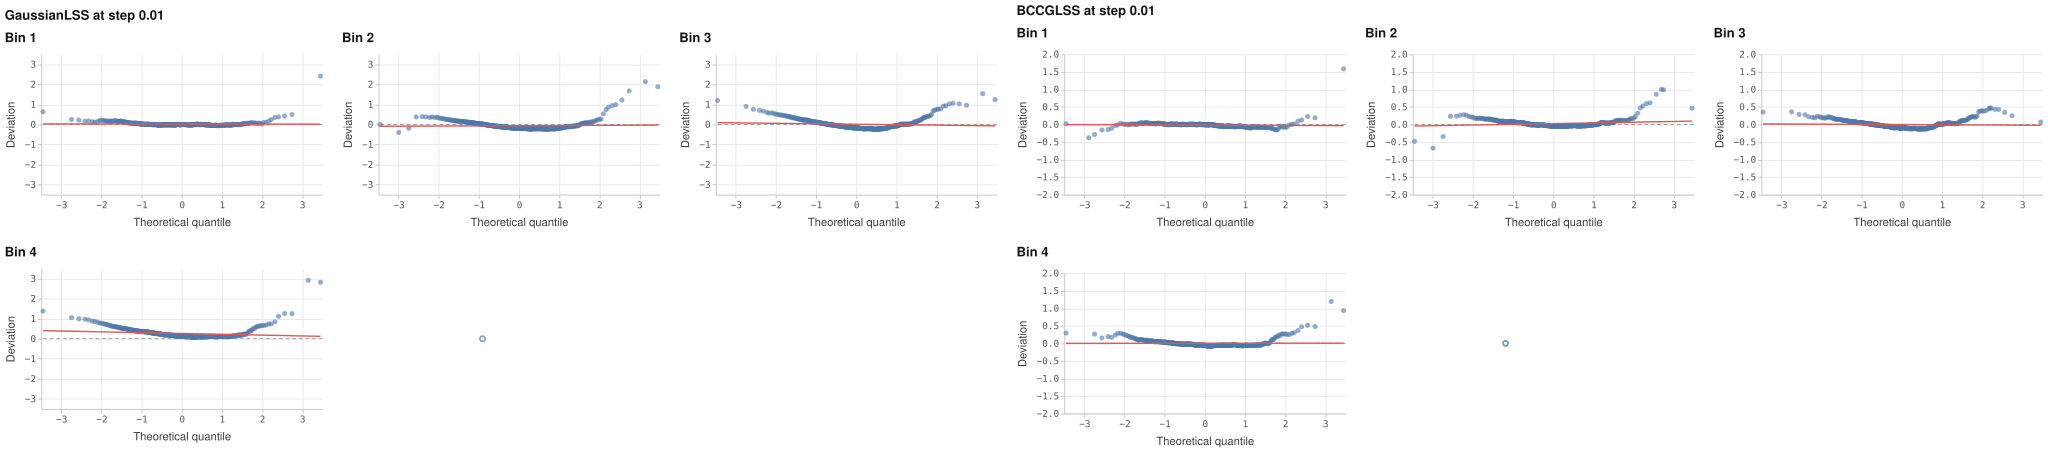

In [8]:
gaussian_worm = mb.plot.plot_worm(gaussian_small).properties(
    title="GaussianLSS at step 0.01")
bccg_worm = mb.plot.plot_worm(bccg).properties(title="BCCGLSS at step 0.01")

gaussian_worm | bccg_worm

In [9]:
from scipy.stats import norm

for label, fit in (("GaussianLSS", gaussian_small), ("BCCGLSS", bccg)):
    z = norm.ppf(np.clip(np.asarray(fit.pit(random_state=0)), 1e-10, 1 - 1e-10))
    centred = z - z.mean()
    print(f"{label:12s} normalised quantile residuals: "
          f"skewness {float((centred ** 3).mean() / z.std() ** 3):+.3f}, "
          f"kurtosis {float((centred ** 4).mean() / z.std() ** 4):.3f}")
print("a correctly specified model gives skewness 0 and kurtosis 3")

GaussianLSS  normalised quantile residuals: skewness +0.868, kurtosis 5.001
BCCGLSS      normalised quantile residuals: skewness +0.332, kurtosis 3.674
a correctly specified model gives skewness 0 and kurtosis 3


The Gaussian worm curves upward at both ends in every age band, indicating too
little mass in both tails. The BCCG worm is flatter and its vertical scale is
smaller, with deviations about half the size.

The normalised quantile residuals quantify this. Skewness falls from 0.868 to
0.332 and kurtosis from 5.00 to 3.67, against 0 and 3 for a correct model. The
third parameter absorbs most of the skew; what remains is tails heavier than
the BCCG represents, visible as the upward hooks in the outermost points of
each panel.


## Fitted skewness parameter

The fitted ν at the working step controls the Box-Cox transformation and thus
the distribution's skewness. The next table averages ν within age quarters;



In [10]:
skewness = np.asarray(bccg.params(type="response")["nu"])
quartiles = np.quantile(age, [0, 0.25, 0.5, 0.75, 1.0])
display(pl.DataFrame([
    {"age band": f"{quartiles[i]:.1f}-{quartiles[i + 1]:.1f}",
     "fitted nu": round(float(skewness[(age >= quartiles[i])
                                       & (age <= quartiles[i + 1])].mean()), 3)}
    for i in range(4)
]))

age band,fitted nu
str,f64
"""0.0-1.9""",0.002
"""1.9-10.4""",-0.388
"""10.4-15.1""",-0.583
"""15.1-21.7""",-0.396


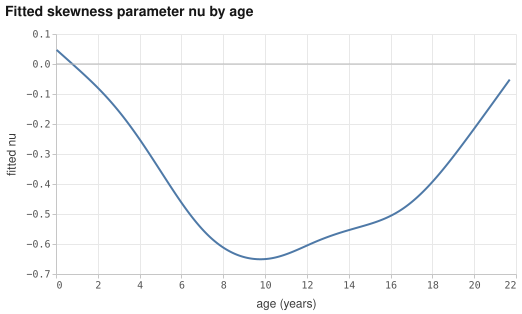

In [11]:
import altair as alt

nu_effect = bccg.partial_effects(parameter="nu")["age"]
nu_df = pl.DataFrame({"age": nu_effect[0], "nu": nu_effect[1]})
line = alt.Chart(nu_df).mark_line(color="#4e79a7").encode(
    x=alt.X("age:Q", title="age (years)"),
    y=alt.Y("nu:Q", title="fitted nu"),
)
zero = alt.Chart(pl.DataFrame({"y": [0.0]})).mark_rule(color="#b7b7b7").encode(y="y:Q")
(line + zero).properties(title="Fitted skewness parameter nu by age",
                         width=460, height=240)

The fitted ν is near zero in infancy, at 0.002, and negative through childhood
and adolescence: −0.388, −0.583 and −0.396 in the last three quarters.

In the Box-Cox parameterisation a negative ν means the transformation required
to make BMI normal is stronger than a logarithm, which corresponds to a
right-skewed distribution and matches the raw skewness in the first table. BMI
is close to symmetric in the first two years and becomes progressively more
skewed after. A chart assuming one shape throughout would be misplaced by an
amount that varies with age.


## Centile chart

The working BCCG fit produces the chart directly. The three curves are the
fitted 3rd, 50th and 97th centiles of BMI at each age.


In [12]:
import altair as alt
# Reuse the declared folds so comparisons differ by model, not by split.
order = np.argsort(age)
age_grid = np.asarray(age)[order]
centile_grid = np.asarray(bccg.centiles(probs=[0.03, 0.5, 0.97],
                                        newdata={"age": age_grid}))
grid_df = pl.DataFrame({
    "age": age_grid,
    "3rd": centile_grid[:, -3],
    "50th": centile_grid[:, -2],
    "97th": centile_grid[:, -1],
})
points = alt.Chart(pl.DataFrame({"age": age, "bmi": bmi})).mark_circle(
    size=9, opacity=0.12, color="#8c8c8c"
).encode(
    x=alt.X("age:Q", title="age (years)"),
    y=alt.Y("bmi:Q", title="BMI"),
)
lines = alt.Chart(grid_df).transform_fold(
    ["3rd", "50th", "97th"], as_=["centile", "value"]
).mark_line().encode(
    x="age:Q",
    y=alt.Y("value:Q", title="BMI"),
    color=alt.Color("centile:N",
                    scale=alt.Scale(domain=["3rd", "50th", "97th"],
                                    range=["#e15759", "#4e79a7", "#59a14f"])),
)
(points + lines).properties(title="Fitted BCCG centiles by age",
                            width=460, height=280)


The centiles follow the shape of the data: narrow and symmetric in infancy,
then spreading with a longer upper tail. The 3rd centile stays close to the
lower edge of the cloud throughout, while the 97th separates from the 50th as
the skew increases. The chart describes the conditional distribution at
each age, including its spread and skewness, rather than only its mean.


## Conclusions

The conditional distribution of BMI in these boys is right-skewed from about
age two onward, the skew varies with age, and a chart that models it places the
outer centiles closer to their targets: 1.97% below the fitted 3rd and 3.73%
above the 97th, against 1.10% and 4.29% for the symmetric Gaussian chart.

The BCCG chart still misfits. Its PIT chi-square is 53.0, above the critical
value of 16.9. With 7294 observations the test detects small departures, but a
departure remains. The published LMS charts for these data use `BCT` (Box-Cox t) or `BCPE` (Box-Cox power exponential), which add a fourth
parameter for kurtosis. mboostrs exposes `BCTLSS` and `BCPELSS`; this study stops at
BCCG to isolate the mean, spread and skewness workflow. A four-parameter comparison
would need its own stopping search and held-out distributional score.

**Out of scope.** Girls, other countries, and other periods.

**A note on the step length.** The step length is 0.01. It is a numerical parameter rather than a
modelling choice, but it should be reported, since running this at the default
step reproduces the broken fit.

The risk path is what identified the problem, and it is cheap to inspect:
boosting minimises in-sample risk, so a rising path indicates a failure of the
optimisation. The other checks used here — centile coverage and the PIT — judge
the deliverable rather than a residual plot. A growth chart is a statement
about the whole distribution at each age, which a workflow ending at the
conditional mean cannot produce.
